# Federalist → Simplified Modern English LoRA Adapter — v3

In [ ]:
!pip install -q -U transformers peft accelerate bitsandbytes datasets spacy sentence-transformers evaluate sacrebleu sacremoses bert-score
!python -m spacy download en_core_web_md -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import os, re, json, random, math, time, gc
from pathlib import Path
from collections import Counter, defaultdict

from google.colab import drive, userdata
drive.mount("/content/drive")

WORKDIR = Path("/content/drive/MyDrive/federalist_lora")
OUT_DIR = WORKDIR / "v3"
OUT_DIR.mkdir(parents=True, exist_ok=True)
assert OUT_DIR.resolve() != WORKDIR.resolve()
EVAL_MODELS_DIR = OUT_DIR / "eval_models"
EVAL_MODELS_DIR.mkdir(exist_ok=True)

BASELINE_TRANSLATIONS = WORKDIR / "translations.jsonl"
V2_CACHE_PATH = WORKDIR / "v2" / "translations_v2.jsonl"

TRANSLATOR_MODEL = "Qwen/Qwen2.5-7B-Instruct"
LOCAL_BATCH = 8
REUSE_BASELINE_TRANSLATIONS = True
REUSE_V2_PLAIN_SHORT = True
SHORT_FRAC = 0.4
PIECE_MIN_WORDS, PIECE_MAX_WORDS = 25, 80
STYLE_WEIGHTS = {"plain": 1.0}
MIN_SIM_LONG, MIN_SIM_SHORT = 0.75, 0.70
RETRY_REJECTED = True

BASE_MODEL = "Qwen/Qwen2.5-3B-Instruct"
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.1
EPOCHS, LR, WEIGHT_DECAY = 2, 1e-4, 0.01
MAX_LEN = 1024
BATCH, GRAD_ACCUM = 2, 8
EVALS_PER_EPOCH, EARLY_STOP_PATIENCE = 4, 3

CHUNK_MIN_WORDS, CHUNK_MAX_WORDS = 80, 220
N_VAL_PAPERS, N_TEST_PAPERS = 4, 5
SEED = 42
random.seed(SEED)
EVAL_TEMPERATURE = 0.3

SIMPLE_WIKI = ("wikimedia/wikipedia", "20231101.simple")
SIMPLE_WIKI_FALLBACK = ("rahular/simple-wikipedia", None)
WIKI_TOPIC_FILTER = True
WIKI_MAX_ARTICLES = 150_000
CLF_BASE, CLF_MAX_LEN, CLF_EPOCHS = "distilroberta-base", 384, 3
ARCHAIC_LM_BASE, MODERN_LM, ARCHAIC_LM_EPOCHS = "gpt2", "gpt2", 3
EVAL_EMBEDDER = "sentence-transformers/all-mpnet-base-v2"
BERTSCORE_MODEL = "roberta-large"
N_BOOT = 2000

try:
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    pass

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import evaluate
_sari = evaluate.load("sari")
print("SARI loads; toy score:", _sari.compute(sources=["About 95 species are currently accepted ."],
                                              predictions=["About 95 you now live ."],
                                              references=[["About 95 species are currently known ."]]))
import sacrebleu, bert_score
from datasets import load_dataset

def open_simple_wiki():
    for name, cfg in (SIMPLE_WIKI, SIMPLE_WIKI_FALLBACK):
        try:
            ds = load_dataset(name, cfg, split="train", streaming=True)
            first = next(iter(ds)); assert "text" in first
            return name, cfg, ds
        except Exception as e:
            print(f"  could not open {name} ({cfg}): {type(e).__name__}: {str(e)[:150]}")
    raise RuntimeError("No Simple Wikipedia source could be opened; set SIMPLE_WIKI in CONFIG to a dataset with a 'text' column.")

wiki_name, wiki_cfg, _ = open_simple_wiki()
print("Simple Wikipedia source:", wiki_name, wiki_cfg)
assert EVAL_EMBEDDER != "all-MiniLM-L6-v2" and "MiniLM" not in EVAL_EMBEDDER, "eval embedder must differ from the filter embedder"

SARI loads; toy score: {'sari': 21.805555555555557}
Simple Wikipedia source: wikimedia/wikipedia 20231101.simple


## 1. Load and segment the corpus
Same loader, chunking and paper-level split as the baseline (same seed, so the val/test papers are identical).

In [ ]:
import zipfile, glob

ZIP_NAME = "Federalist_Papers_Separated.zip"
zip_path = WORKDIR / ZIP_NAME
if not zip_path.exists():
    zip_path = OUT_DIR / ZIP_NAME
if not zip_path.exists():
    from google.colab import files
    print(f"Upload {ZIP_NAME}")
    up = files.upload()
    zip_path.write_bytes(up[next(k for k in up if k.endswith(".zip"))])

txt_dir = Path("/content/federalist_txt")
if not txt_dir.exists():
    with zipfile.ZipFile(zip_path) as z: z.extractall(txt_dir)

papers, meta = {}, {}
for fp in sorted(glob.glob(str(txt_dir / "**" / "Federalist_*.txt"), recursive=True)):
    t = Path(fp).read_text(encoding="utf-8", errors="ignore").replace("\r\n", "\n").strip()
    head, _, rest = t.partition("\n\n")
    n = int(re.search(r"No\.\s*(\d+)", head).group(1))
    papers[n] = rest
    meta[n] = head.splitlines()[-1].replace("by ", "").strip()
print("papers found:", len(papers), "| missing:", sorted(set(range(1, 86)) - set(papers)))

def split_sentences(t):
    return re.split(r"(?<=[.!?])\s+(?=[A-Z\"'(])", t.strip())

def paper_to_chunks(txt):
    paras = [re.sub(r"\s+", " ", p).strip() for p in re.split(r"\n\s*\n", txt)]
    paras = [p for p in paras if p]
    for i, p in enumerate(paras[:10]):
        if p.lower().startswith("to the people of the state of new york"):
            paras = paras[i + 1:]
            break
    paras = [p for p in paras if not re.fullmatch(r"(PUBLIUS|HAMILTON|MADISON|JAY)[. ]*", p)]
    units = []
    for p in paras:
        if len(p.split()) <= CHUNK_MAX_WORDS:
            units.append(p); continue
        cur = []
        for sent in split_sentences(p):
            if cur and len(" ".join(cur + [sent]).split()) > CHUNK_MAX_WORDS:
                units.append(" ".join(cur)); cur = []
            cur.append(sent)
        if cur: units.append(" ".join(cur))
    chunks, cur = [], ""
    for u in units:
        if cur and len((cur + " " + u).split()) > CHUNK_MAX_WORDS:
            chunks.append(cur); cur = u
        else:
            cur = (cur + " " + u).strip()
        if len(cur.split()) >= CHUNK_MIN_WORDS:
            chunks.append(cur); cur = ""
    if cur and len(cur.split()) >= 30:
        chunks.append(cur)
    return chunks

def make_pieces(text, lo=PIECE_MIN_WORDS, hi=PIECE_MAX_WORDS):
    pieces, cur = [], []
    for s in split_sentences(text):
        if cur and len(" ".join(cur + [s]).split()) > hi:
            pieces.append(" ".join(cur)); cur = []
        cur.append(s)
        if len(" ".join(cur).split()) >= lo:
            pieces.append(" ".join(cur)); cur = []
    if cur:
        tail = " ".join(cur)
        if pieces and len(tail.split()) < 20:
            pieces[-1] += " " + tail
        elif len(tail.split()) >= 20:
            pieces.append(tail)
    return pieces

# split by paper so val/test are never seen in training (identical to baseline)
nums = sorted(papers)
random.shuffle(nums)
test_p = set(nums[:N_TEST_PAPERS]); val_p = set(nums[N_TEST_PAPERS:N_TEST_PAPERS + N_VAL_PAPERS])

records = []     # all long chunks, exactly as in the baseline
for n in sorted(papers):
    split = "test" if n in test_p else "val" if n in val_p else "train"
    for j, c in enumerate(c for c in paper_to_chunks(papers[n]) if len(c.split()) >= 40):
        records.append({"id": f"fed{n:02d}_{j:02d}", "paper": n, "split": split, "original": c, "kind": "long", "style": "plain"})

rng = random.Random(SEED + 1)
train_long = [r for r in records if r["split"] == "train"]
replace_ids = {r["id"] for r in rng.sample(train_long, int(SHORT_FRAC * len(train_long)))}
style_names, style_w = zip(*STYLE_WEIGHTS.items())
short_records = []
for r in train_long:
    if r["id"] in replace_ids:
        for k, piece in enumerate(make_pieces(r["original"])):
            short_records.append({"id": f"{r['id']}_s{k}", "paper": r["paper"], "split": "train", "original": piece,
                                  "kind": "short", "style": rng.choices(style_names, style_w)[0]})
items = [r for r in records if r["id"] not in replace_ids] + short_records

print("long chunks:", Counter(r["split"] for r in records))
print("items to use:", Counter((r["split"], r["kind"]) for r in items))
print("short-piece styles:", Counter(r["style"] for r in short_records))
print("short piece length (words): mean %.0f" % (sum(len(r["original"].split()) for r in short_records) / max(1, len(short_records))))
print("\nSample short piece:\n", short_records[0]["original"])

papers found: 85 | missing: []
long chunks: Counter({'train': 1086, 'test': 69, 'val': 65})
items to use: Counter({('train', 'short'): 1438, ('train', 'long'): 652, ('test', 'long'): 69, ('val', 'long'): 65})
short-piece styles: Counter({'plain': 1438})
short piece length (words): mean 45

Sample short piece:
 Among the most formidable of the obstacles which the new Constitution will have to encounter may readily be distinguished the obvious interest of a certain class of men in every State to resist all changes which may hazard a diminution of the power, emolument, and consequence of the offices they hold under the State establishments; and the perverted ambition of another class of men, who will either hope to aggrandize themselves by the confusions of their country, or will flatter themselves with fairer prospects of elevation from the subdivision of the empire into several partial confederacies than from its union under one government.


## 2. Synthetic parallel data (Federalist → plain modern English), local open model, no API
- Long chunks reuse the baseline's cached paraphrases (read-only) when `REUSE_BASELINE_TRANSLATIONS` is on. Anything missing is generated with `TRANSLATOR_MODEL`.
- Short pieces reuse v2's cached **plain** paraphrases when the id matches; otherwise they are generated. The similarity filter below re-checks every reused paraphrase against its own original text, so a stale cache entry cannot slip through.
- Everything is cached to `v3/translations_v3.jsonl`, so you can stop and resume.
- Train pairs whose paraphrase is too far from the original (embedding similarity) or the wrong length are retried once with a stricter "keep every detail" prompt, then dropped if they still fail. Val/test pairs only get the length check.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

RULES = ("You rewrite 18th-century political prose into modern American English. Rules: "
         "(1) preserve every claim, example, qualification, and logical connective, and do not add anything that is not in the text; "
         "(2) keep all proper names (people, places, institutions, nations) exactly as written; "
         "(3) {style} "
         "(4) do not add commentary or summarize; "
         "(5) output only the rewritten text as a single paragraph.")
STYLE_TEXT = {
    "plain": "use short, direct sentences and everyday vocabulary, no archaic words, no rhetorical flourishes;",
}
STRICT_SUFFIX = (" IMPORTANT: a previous attempt dropped or changed details. Work sentence by sentence, keep every detail, "
                 "and make the rewrite about as long as the original.")

def system_for(item, strict=False):
    return RULES.format(style=STYLE_TEXT[item["style"]]) + (STRICT_SUFFIX if strict else "")

V3_CACHE = OUT_DIR / "translations_v3.jsonl"
cache = {}
if V3_CACHE.exists():
    for line in V3_CACHE.read_text(encoding="utf-8").splitlines():
        d = json.loads(line); cache[d["id"]] = d

def save(item, out, attempt, source):
    d = {"id": item["id"], "modern": out, "style": item["style"], "attempt": attempt, "source": source}
    cache[item["id"]] = d
    with open(V3_CACHE, "a", encoding="utf-8") as f:
        f.write(json.dumps(d) + "\n")

if REUSE_BASELINE_TRANSLATIONS and BASELINE_TRANSLATIONS.exists():
    base_tr = {}
    for line in BASELINE_TRANSLATIONS.read_text(encoding="utf-8").splitlines():
        d = json.loads(line); base_tr[d["id"]] = d["modern"]
    n_reused = 0
    for r in items:
        if r["kind"] == "long" and r["id"] not in cache and r["id"] in base_tr:
            save(r, base_tr[r["id"]], 1, "baseline"); n_reused += 1
    print(f"reused {n_reused} baseline paraphrases (baseline file untouched)")

if REUSE_V2_PLAIN_SHORT and V2_CACHE_PATH.exists():
    v2c = {}
    for line in V2_CACHE_PATH.read_text(encoding="utf-8").splitlines():
        d = json.loads(line); v2c[d["id"]] = d
    n_v2 = 0
    for r in items:
        d = v2c.get(r["id"])
        if r["kind"] == "short" and r["id"] not in cache and d is not None and d.get("style") == "plain":
            save(r, d["modern"], d.get("attempt", 1), "v2 cache"); n_v2 += 1
    print(f"reused {n_v2} plain short-piece paraphrases from the v2 cache (they still go through the similarity filter)")

BAD_START = re.compile(r"^(here is|here's|sure|certainly|rewritten|modern english)", re.I)
def clean_translation(o):
    o = re.sub(r"\s*\n+\s*", " ", o.strip()).strip()
    if not o or BAD_START.match(o): return None
    return o

tmodel = ttok = None
def get_translator():
    global tmodel, ttok
    if tmodel is None:
        ttok = AutoTokenizer.from_pretrained(TRANSLATOR_MODEL, padding_side="left")
        if ttok.pad_token is None: ttok.pad_token = ttok.eos_token
        tmodel = AutoModelForCausalLM.from_pretrained(
            TRANSLATOR_MODEL, device_map={"": 0},
            quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                   bnb_4bit_compute_dtype=torch.float16))
        tmodel.eval()
    return tmodel, ttok

@torch.no_grad()
def translate_batch(batch, temperature, strict):
    tm, tt = get_translator()
    prompts = [tt.apply_chat_template(
        [{"role": "system", "content": system_for(r, strict)}, {"role": "user", "content": r["original"]}],
        tokenize=False, add_generation_prompt=True) for r in batch]
    enc = tt(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(0)
    max_new = int(min(520, 2.0 * max(len(r["original"].split()) for r in batch) + 40))
    out = tm.generate(**enc, max_new_tokens=max_new, do_sample=True, temperature=temperature, top_p=0.9,
                      repetition_penalty=1.05, pad_token_id=tt.pad_token_id)
    return [clean_translation(tt.decode(o[enc["input_ids"].shape[1]:], skip_special_tokens=True)) for o in out]

def run_pass(batch_items, attempt, temperature, strict=False):
    if not batch_items:
        return
    batch_items = sorted(batch_items, key=lambda r: len(r["original"]))
    t0 = time.time()
    for i in range(0, len(batch_items), LOCAL_BATCH):
        batch = batch_items[i:i + LOCAL_BATCH]
        try:
            outs = translate_batch(batch, temperature, strict)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache(); outs = []
            for r in batch: outs += translate_batch([r], temperature, strict)
        for r, o in zip(batch, outs):
            if o: save(r, o, attempt, TRANSLATOR_MODEL)
        if (i // LOCAL_BATCH) % 10 == 0 or i + LOCAL_BATCH >= len(batch_items):
            print(f"  attempt {attempt}: {min(i + LOCAL_BATCH, len(batch_items))}/{len(batch_items)}  ({(time.time()-t0)/60:.1f} min)")

todo = [r for r in items if r["id"] not in cache]
print(f"{len(cache)} cached, {len(todo)} to translate with {TRANSLATOR_MODEL}")
run_pass(todo, attempt=1, temperature=0.3)
print("first pass done; translations available for", sum(r["id"] in cache for r in items), "/", len(items), "items")

reused 0 baseline paraphrases (baseline file untouched)
reused 0 plain short-piece paraphrases from the v2 cache (they still go through the similarity filter)
2223 cached, 1 to translate with Qwen/Qwen2.5-7B-Instruct


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

  attempt 1: 1/1  (0.1 min)
first pass done; translations available for 2223 / 2224 items


In [ ]:
import numpy as np
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("all-MiniLM-L6-v2", device="cuda" if torch.cuda.is_available() else "cpu")


_ntok = [len(embedder.tokenizer(r["original"])["input_ids"]) for r in items]
print(f"originals longer than 256 tokens: {sum(n > 256 for n in _ntok)}/{len(_ntok)} (max {max(_ntok)}) -> raising max_seq_length to 512")
embedder.max_seq_length = 512

def sims(a_texts, b_texts):
    a = embedder.encode(a_texts, batch_size=64, convert_to_tensor=True, normalize_embeddings=True, show_progress_bar=False)
    b = embedder.encode(b_texts, batch_size=64, convert_to_tensor=True, normalize_embeddings=True, show_progress_bar=False)
    return (a * b).sum(1).cpu().tolist()

def score(subset):
    ready = [r for r in subset if r["id"] in cache]
    for r, v in zip(ready, sims([r["original"] for r in ready], [cache[r["id"]]["modern"] for r in ready])):
        r["sim"] = v

def status(r):
    d = cache.get(r["id"])
    if d is None: return "no_translation"
    ratio = len(d["modern"].split()) / max(1, len(r["original"].split()))
    if not 0.4 <= ratio <= 1.6: return "length_ratio"
    if r["split"] == "train":
        thr = MIN_SIM_SHORT if r["kind"] == "short" else MIN_SIM_LONG
        if r.get("sim", 0.0) < thr: return "low_similarity"
    return "ok"

def sim_report(tag):
    for kind in ("long", "short"):
        v = np.array([r["sim"] for r in items if r["split"] == "train" and r["kind"] == kind and "sim" in r])
        if len(v):
            print(f"  [{tag}] train {kind:5s} n={len(v):4d}  p5={np.percentile(v,5):.3f}  p25={np.percentile(v,25):.3f}  median={np.median(v):.3f}")

score(items)
sim_report("before retry")
print("status before retry:", Counter((r["split"], status(r)) for r in items))

bad = [r for r in items if r["split"] == "train" and status(r) in ("low_similarity", "length_ratio") and cache[r["id"]]["attempt"] == 1]
print(f"\n{len(bad)} train items rejected on the first pass")
if RETRY_REJECTED and bad:
    run_pass(bad, attempt=2, temperature=0.2, strict=True)
    score(bad)
    sim_report("after retry")

print("\nfinal status:", Counter((r["split"], r["kind"], status(r)) for r in items))

tmodel = ttok = None
gc.collect(); torch.cuda.empty_cache()

with open(OUT_DIR / "pairs_v3_audit.jsonl", "w", encoding="utf-8") as f:
    for r in items:
        f.write(json.dumps({"id": r["id"], "split": r["split"], "kind": r["kind"], "style": r["style"], "sim": r.get("sim"),
                            "status": status(r), "original": r["original"], "modern": cache.get(r["id"], {}).get("modern")}) + "\n")
print("audit written to", OUT_DIR / "pairs_v3_audit.jsonl")

short_ok = [r for r in items if r["kind"] == "short" and status(r) == "ok"]
for r in short_ok[:3]:
    print(f"\n[{r['style']}, sim={r['sim']:.2f}]\nORIGINAL: {r['original'][:260]}\nMODERN:   {cache[r['id']]['modern'][:260]}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (266 > 256). Running this sequence through the model will result in indexing errors


originals longer than 256 tokens: 72/2224 (max 334) -> raising max_seq_length to 512
  [before retry] train long  n= 652  p5=0.715  p25=0.791  median=0.844
  [before retry] train short n=1437  p5=0.653  p25=0.785  median=0.862
status before retry: Counter({('train', 'ok'): 1924, ('train', 'low_similarity'): 161, ('test', 'ok'): 69, ('val', 'ok'): 65, ('train', 'length_ratio'): 4, ('train', 'no_translation'): 1})

0 train items rejected on the first pass

final status: Counter({('train', 'short', 'ok'): 1329, ('train', 'long', 'ok'): 595, ('train', 'short', 'low_similarity'): 106, ('test', 'long', 'ok'): 69, ('val', 'long', 'ok'): 65, ('train', 'long', 'low_similarity'): 55, ('train', 'long', 'length_ratio'): 2, ('train', 'short', 'length_ratio'): 2, ('train', 'short', 'no_translation'): 1})
audit written to /content/drive/MyDrive/federalist_lora/v3/pairs_v3_audit.jsonl

[plain, sim=0.73]
ORIGINAL: Among the most formidable of the obstacles which the new Constitution will have to encoun

## 3. Entity masking (direction flipped)
Placeholders (`[PERSON_1]`, `[GPE_2]`, ...) are now created from the **Federalist input** and applied to the paraphrase target. An entity that appears only in the paraphrase is left as real text, never replaced with an unnumbered tag. At generation time the same masking is applied to the input and `unmask` restores the names in the output.

In [ ]:
import spacy
nlp = spacy.load("en_core_web_md", disable=["lemmatizer", "parser"])
KEEP = {"PERSON", "ORG", "GPE", "LOC", "NORP", "FAC", "EVENT"}

def norm_key(t):
    t = t.lower().strip()
    t = re.sub(r"^(the|a|an)\s+", "", t)
    return re.sub(r"['’]s$", "", t)

def mask_text(text, mapping, counts, surface, create):
    doc = nlp(text); out, last = [], 0
    for ent in doc.ents:
        if ent.label_ not in KEEP: continue
        key = norm_key(ent.text)
        if key in mapping:
            repl = mapping[key]
        elif create:
            counts[ent.label_] += 1
            repl = f"[{ent.label_}_{counts[ent.label_]}]"
            mapping[key] = repl; surface[repl] = ent.text
        else:
            continue
        out += [text[last:ent.start_char], repl]; last = ent.end_char
    out.append(text[last:])
    return "".join(out)

def mask_pair(original, modern):
    mapping, counts, surface = {}, defaultdict(int), {}
    o = mask_text(original, mapping, counts, surface, create=True)
    m = mask_text(modern, mapping, counts, surface, create=False)
    return o, m

def mask_input(text):
    mapping, counts, surface = {}, defaultdict(int), {}
    return mask_text(text, mapping, counts, surface, True), surface

def unmask(text, surface):
    for ph, s in surface.items():
        text = text.replace(ph, s)
    return text

pairs = []
for r in items:
    if status(r) != "ok": continue
    p = {**r, "modern": cache[r["id"]]["modern"]}
    p["original_masked"], p["modern_masked"] = mask_pair(p["original"], p["modern"])
    pairs.append(p)

stray = Counter(t for p in pairs for t in re.findall(r"\[[A-Z]+\]", p["modern_masked"] + " " + p["original_masked"]))
print("unnumbered tags anywhere in the training pairs (should be empty):", dict(stray))

n_ph = n_kept = 0
for p in pairs:
    for ph in set(re.findall(r"\[[A-Z]+_\d+\]", p["original_masked"])):
        n_ph += 1; n_kept += ph in p["modern_masked"]
print(f"placeholders from the input that survive into the target: {n_kept}/{n_ph}")
ex = next(p for p in pairs if "[" in p["original_masked"])
print("\nFEDERALIST (masked, INPUT): ", ex["original_masked"][:300])
print("\nMODERN (masked, TARGET):    ", ex["modern_masked"][:300])

unnumbered tags anywhere in the training pairs (should be empty): {}
placeholders from the input that survive into the target: 1504/2352

FEDERALIST (masked, INPUT):  AFTER an unequivocal experience of the inefficiency of the subsisting federal government, you are called upon to deliberate on a new Constitution for [GPE_1]. The subject speaks its own importance; comprehending in its consequences nothing less than the existence of the UNION, the safety and welfare

MODERN (masked, TARGET):     Experience has clearly shown that the current federal government does not work. Because of this, you are now called to consider a new Constitution for [GPE_1]. The subject is obviously important. Its outcome will determine the very existence of the UNION, the safety and well-being of the parts that 


## 4. Build the dataset
The system prompt now asks for simplification. The same prompt is used for training and for generating with the adapter.

In [ ]:
SYSTEM_PROMPT = ("Rewrite the user's text in simple, plain modern English: short, direct sentences, everyday vocabulary, no archaic words. "
                 "Preserve every claim and its meaning exactly. Keep bracketed placeholders such as [PERSON_1] unchanged.")

def msgs(user, assistant=None):
    m = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]
    if assistant is not None: m.append({"role": "assistant", "content": assistant})
    return m

train_pairs = [p for p in pairs if p["split"] == "train"]
val_pairs   = [p for p in pairs if p["split"] == "val"]
test_pairs  = [p for p in pairs if p["split"] == "test"]
print("train:", len(train_pairs), Counter(p["kind"] for p in train_pairs), "| val:", len(val_pairs), "| test:", len(test_pairs))
assert all(p["kind"] == "long" for p in test_pairs), "test set should contain only full-length chunks"

train: 1924 Counter({'short': 1329, 'long': 595}) | val: 65 | test: 69


## 5. Evaluation models: style classifier and archaic language model
Both are trained **before** the adapter, on data that never touches the adapter's training objective, and are used **only for scoring**. They are saved under `v3/eval_models/` and skipped on re-run if already trained.

- **Style classifier** (`distilroberta-base`, 2 classes): class 0 = 18th-century (Federalist), class 1 = simplified modern (Simple English Wikipedia). Federalist side = TRAIN papers only (VAL papers for validation); the TEST papers are never seen. Segments come in two sizes (chunk-sized and piece-sized) and the Wikipedia segments are length-matched to the Federalist ones, so length is not a shortcut. Wikipedia articles are split train/val *by article*.
- **Archaic LM**: GPT-2 fine-tuned on the Federalist TRAIN papers. The **modern LM** is stock GPT-2. The score is `PPL_archaic / PPL_modern` per output: **higher = reads more modern**.

In [ ]:
import numpy as np
import torch
from datasets import Dataset, load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification, BitsAndBytesConfig,
                          Trainer, TrainingArguments, DataCollatorWithPadding, DataCollatorForLanguageModeling)

fed_chunks = {s: [r["original"] for r in records if r["split"] == s] for s in ("train", "val")}
fed_pieces = {s: [p for c in fed_chunks[s] for p in make_pieces(c)] for s in ("train", "val")}
print({k: len(v) for k, v in {**{f"fed chunks {s}": fed_chunks[s] for s in fed_chunks}, **{f"fed pieces {s}": fed_pieces[s] for s in fed_pieces}}.items()})

TOPIC_WORDS = set("""government governments law laws constitution constitutional political politics election elections congress parliament senate
court courts tax taxes taxation treaty treaties army military war wars citizen citizens rights republic democracy president king kingdom
empire nation nations trade commerce economy economic revenue debt vote voting justice judge judges legislature legislative power powers
public officers office liberty authority""".split())
def topic_hits(t): return sum(w in TOPIC_WORDS for w in re.findall(r"[a-z]+", t.lower()))

def wiki_sentences(text):
    lines = [l.strip() for l in text.split("\n") if len(l.split()) >= 8 and l.strip()[-1] in ".!?"]
    return [s for l in lines for s in split_sentences(l)]

def group_sents(sents, lo, hi, rng):
    out, cur, target = [], [], rng.randint(lo, hi)
    for s in sents:
        cur.append(s)
        if len(" ".join(cur).split()) >= target:
            out.append(" ".join(cur)); cur = []; target = rng.randint(lo, hi)
    return out

need = {("train", "chunk"): len(fed_chunks["train"]), ("train", "piece"): len(fed_pieces["train"]),
        ("val", "chunk"): len(fed_chunks["val"]),     ("val", "piece"): len(fed_pieces["val"])}
SIZES = {"chunk": (CHUNK_MIN_WORDS, CHUNK_MAX_WORDS), "piece": (PIECE_MIN_WORDS, PIECE_MAX_WORDS)}
pool = {k: [] for k in need}
clf_dir = EVAL_MODELS_DIR / "style_clf"
alm_dir = EVAL_MODELS_DIR / "archaic_lm"

if not (clf_dir / "config.json").exists():
    print("streaming Simple English Wikipedia ...", wiki_name, wiki_cfg)
    stream = load_dataset(wiki_name, wiki_cfg, split="train", streaming=True).shuffle(seed=SEED, buffer_size=10_000)
    rngw = random.Random(SEED + 2); n_art = 0
    for art in stream:
        n_art += 1
        split = "val" if n_art % 8 == 0 else "train"
        sents = wiki_sentences(art["text"])
        if len(sents) >= 4:
            for kind, (lo, hi) in SIZES.items():
                if len(pool[(split, kind)]) >= need[(split, kind)]: continue
                for seg in group_sents(sents, lo, hi, rngw):
                    nw = len(seg.split())
                    if nw > 1.3 * hi: continue
                    if WIKI_TOPIC_FILTER and topic_hits(seg) < max(2, nw // 30): continue
                    if len(pool[(split, kind)]) < need[(split, kind)]: pool[(split, kind)].append(seg)
        if all(len(pool[k]) >= need[k] for k in need) or n_art >= WIKI_MAX_ARTICLES: break
    print(f"scanned {n_art} articles; Wikipedia segments collected vs needed:",
          {f"{k[0]}/{k[1]}": f"{len(pool[k])}/{need[k]}" for k in need})

    def build(split):
        neg, pos = [], []
        for kind, fed in (("chunk", fed_chunks[split]), ("piece", fed_pieces[split])):
            n = min(len(fed), len(pool[(split, kind)]))
            rr = random.Random(SEED + 3)
            neg += rr.sample(fed, n); pos += rr.sample(pool[(split, kind)], n)
        texts = neg + pos; labels = [0] * len(neg) + [1] * len(pos)
        order = list(range(len(texts))); random.Random(SEED + 4).shuffle(order)
        return [texts[i] for i in order], [labels[i] for i in order]
    (tr_x, tr_y), (va_x, va_y) = build("train"), build("val")
    print("classifier train:", Counter(tr_y), "| val:", Counter(va_y))
    print("mean words  archaic: %.0f  modern: %.0f  (should be close)" % (
        np.mean([len(x.split()) for x, y in zip(tr_x, tr_y) if y == 0]), np.mean([len(x.split()) for x, y in zip(tr_x, tr_y) if y == 1])))
    print("\nexample modern training segment:\n ", next(x for x, y in zip(tr_x, tr_y) if y == 1)[:300])

    ctok0 = AutoTokenizer.from_pretrained(CLF_BASE)
    enc_fn = lambda b: ctok0(b["text"], truncation=True, max_length=CLF_MAX_LEN)
    tr_ds = Dataset.from_dict({"text": tr_x, "label": tr_y}).map(enc_fn, batched=True)
    va_ds = Dataset.from_dict({"text": va_x, "label": va_y}).map(enc_fn, batched=True)
    cm = AutoModelForSequenceClassification.from_pretrained(CLF_BASE, num_labels=2)
    cargs = TrainingArguments(output_dir=str(EVAL_MODELS_DIR / "clf_tmp"), num_train_epochs=CLF_EPOCHS, learning_rate=2e-5,
                              per_device_train_batch_size=16, per_device_eval_batch_size=32, weight_decay=0.01, warmup_steps=max(1, round(0.1 * math.ceil(len(tr_x) / 16) * CLF_EPOCHS)),
                              eval_strategy="epoch", save_strategy="no", report_to="none", fp16=torch.cuda.is_available(), seed=SEED)
    ctr = Trainer(model=cm, args=cargs, train_dataset=tr_ds, eval_dataset=va_ds, data_collator=DataCollatorWithPadding(ctok0),
                  compute_metrics=lambda p: {"accuracy": float((p.predictions.argmax(-1) == p.label_ids).mean())})
    ctr.train()
    pred = ctr.predict(va_ds); yhat = pred.predictions.argmax(-1); ytrue = np.array(va_y)
    CLF_VAL = {"accuracy": float((yhat == ytrue).mean()),
               "archaic_recall": float((yhat[ytrue == 0] == 0).mean()), "modern_recall": float((yhat[ytrue == 1] == 1).mean())}
    print("classifier validation (held-out VAL papers vs held-out Wikipedia articles):", CLF_VAL)
    cm.save_pretrained(str(clf_dir)); ctok0.save_pretrained(str(clf_dir))
    (EVAL_MODELS_DIR / "style_clf_val.json").write_text(json.dumps(CLF_VAL))
    del cm, ctr; gc.collect(); torch.cuda.empty_cache()
else:
    CLF_VAL = json.loads((EVAL_MODELS_DIR / "style_clf_val.json").read_text()) if (EVAL_MODELS_DIR / "style_clf_val.json").exists() else {}
    print("style classifier already trained ->", clf_dir, CLF_VAL)

if not (alm_dir / "config.json").exists():
    ltok0 = AutoTokenizer.from_pretrained(ARCHAIC_LM_BASE)
    ltok0.pad_token = ltok0.eos_token
    def blocks(texts, size=256):
        ids = []
        for t in texts: ids += ltok0(t, add_special_tokens=False)["input_ids"] + [ltok0.eos_token_id]
        return Dataset.from_dict({"input_ids": [ids[i:i + size] for i in range(0, len(ids) - size + 1, size)]})
    tb, vb = blocks(fed_chunks["train"]), blocks(fed_chunks["val"])
    print("archaic LM blocks: train", len(tb), "| val", len(vb))
    am = AutoModelForCausalLM.from_pretrained(ARCHAIC_LM_BASE)
    aargs = TrainingArguments(output_dir=str(EVAL_MODELS_DIR / "alm_tmp"), num_train_epochs=ARCHAIC_LM_EPOCHS, learning_rate=5e-5,
                              per_device_train_batch_size=8, per_device_eval_batch_size=8, weight_decay=0.01, warmup_steps=max(1, round(0.05 * math.ceil(len(tb) / 8) * ARCHAIC_LM_EPOCHS)),
                              eval_strategy="epoch", save_strategy="no", report_to="none", fp16=torch.cuda.is_available(), seed=SEED)
    atr = Trainer(model=am, args=aargs, train_dataset=tb, eval_dataset=vb, data_collator=DataCollatorForLanguageModeling(ltok0, mlm=False))
    base_loss = atr.evaluate()["eval_loss"]
    atr.train()
    tuned_loss = atr.evaluate()["eval_loss"]
    print(f"VAL-paper Federalist perplexity: stock {ARCHAIC_LM_BASE} {math.exp(base_loss):.1f}  ->  fine-tuned {math.exp(tuned_loss):.1f}  (should drop clearly)")
    am.save_pretrained(str(alm_dir)); ltok0.save_pretrained(str(alm_dir))
    del am, atr; gc.collect(); torch.cuda.empty_cache()
else:
    print("archaic LM already trained ->", alm_dir)

{'fed chunks train': 1086, 'fed chunks val': 65, 'fed pieces train': 3655, 'fed pieces val': 212}
streaming Simple English Wikipedia ... wikimedia/wikipedia 20231101.simple
scanned 4534 articles; Wikipedia segments collected vs needed: {'train/chunk': '1086/1086', 'train/piece': '3655/3655', 'val/chunk': '65/65', 'val/piece': '212/212'}
classifier train: Counter({1: 4741, 0: 4741}) | val: Counter({1: 277, 0: 277})
mean words  archaic: 70  modern: 84  (should be close)

example modern training segment:
  He sponsored the Authorized King James Version of the Bible. James was a target of the Gunpowder Plot. A group of Catholics planned to blow up the Houses of Parliament on 5 November 1605 during a ceremony while James was in the building. The plot was stopped when a member of the group, Guy Fawkes, w


Map:   0%|          | 0/9482 [00:00<?, ? examples/s]

Map:   0%|          | 0/554 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: distilroberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy
1,0.100971,0.010371,0.996390
2,0.004871,0.029964,0.996390
3,0.002786,0.007486,0.998195


... (14 outputs left out)

Epoch,Training Loss,Validation Loss
1,No log,3.156871
2,No log,3.122967
3,No log,3.116365


Training Loss,Validation Loss,Epoch
No log,3.116365,3


VAL-paper Federalist perplexity: stock gpt2 31.7  ->  fine-tuned 22.6  (should drop clearly)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 6. Load base model in 4-bit and attach LoRA

In [ ]:
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from datasets import Dataset

bf16_ok = torch.cuda.is_bf16_supported()
compute_dtype = torch.bfloat16 if bf16_ok else torch.float16

tok = AutoTokenizer.from_pretrained(BASE_MODEL)
if tok.pad_token is None: tok.pad_token = tok.eos_token

model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                           bnb_4bit_use_double_quant=True,
                                           bnb_4bit_compute_dtype=compute_dtype),
    device_map={"": 0}, torch_dtype=compute_dtype)
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
model = get_peft_model(model, LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                                         target_modules="all-linear", task_type="CAUSAL_LM"))
model.print_trainable_parameters()

def encode(p):
    prompt = tok.apply_chat_template(msgs(p["original_masked"]), tokenize=False, add_generation_prompt=True)
    full   = tok.apply_chat_template(msgs(p["original_masked"], p["modern_masked"]), tokenize=False)
    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    f_ids = tok(full,   add_special_tokens=False)["input_ids"][:MAX_LEN]
    labels = [-100] * len(p_ids) + f_ids[len(p_ids):]
    return {"input_ids": f_ids, "labels": labels[:len(f_ids)]}

train_ds = Dataset.from_list([encode(p) for p in train_pairs])
val_ds   = Dataset.from_list([encode(p) for p in val_pairs])
print("max seq len:", max(len(x) for x in train_ds["input_ids"]),
      "| trainable label tokens (avg):", sum(sum(l != -100 for l in x) for x in train_ds["labels"]) // len(train_ds))

def collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids  = torch.tensor([b["input_ids"] + [tok.pad_token_id] * (L - len(b["input_ids"])) for b in batch])
    labs = torch.tensor([b["labels"] + [-100] * (L - len(b["labels"])) for b in batch])
    att  = torch.tensor([[1] * len(b["input_ids"]) + [0] * (L - len(b["input_ids"])) for b in batch])
    return {"input_ids": ids, "labels": labs, "attention_mask": att}

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (3 outputs left out)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607
max seq len: 754 | trainable label tokens (avg): 76


## 7. Train
Validation runs 4x per epoch; training stops early if validation loss fails to improve for 3 evals, and the **best** checkpoint is loaded at the end (so the saved adapter is the best one, not the last). Checkpoints go to `v3/checkpoints`, the final adapter to `v3/adapter`.

In [ ]:
steps_per_epoch = math.ceil(len(train_ds) / (BATCH * GRAD_ACCUM))
total_steps = steps_per_epoch * EPOCHS
warmup = max(1, round(total_steps * 0.05))
eval_every = max(5, steps_per_epoch // EVALS_PER_EPOCH)
print(f"{steps_per_epoch} steps/epoch, {total_steps} total, warmup {warmup}, eval/save every {eval_every} steps")

args = TrainingArguments(
    output_dir=str(OUT_DIR / "checkpoints"),
    num_train_epochs=EPOCHS, learning_rate=LR, lr_scheduler_type="cosine",
    warmup_steps=warmup,
    per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
    gradient_accumulation_steps=GRAD_ACCUM,
    bf16=bf16_ok, fp16=not bf16_ok,
    optim="paged_adamw_8bit", weight_decay=WEIGHT_DECAY, max_grad_norm=0.3,
    logging_steps=10, logging_strategy="steps",
    eval_strategy="steps", eval_steps=eval_every,
    save_strategy="steps", save_steps=eval_every, save_total_limit=3,
    load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
    report_to="none", disable_tqdm=False, remove_unused_columns=False,
)
model.config.use_cache = False
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collate,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOP_PATIENCE)])
trainer.train()

ADAPTER_DIR = OUT_DIR / "adapter"
model.save_pretrained(ADAPTER_DIR); tok.save_pretrained(ADAPTER_DIR)
print("best checkpoint:", trainer.state.best_model_checkpoint, "| best eval_loss:", trainer.state.best_metric)
print("saved BEST adapter to", ADAPTER_DIR)

121 steps/epoch, 242 total, warmup 12, eval/save every 30 steps


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss,Validation Loss
30,0.676917,0.686637
60,0.620524,0.659721
90,0.630897,0.643542
120,0.596693,0.640036
150,0.504740,0.639076
180,0.495691,0.635415
210,0.485522,0.634102
240,0.485903,0.633520
242,0.485903,0.633565


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/pyt

best checkpoint: /content/drive/MyDrive/federalist_lora/v3/checkpoints/checkpoint-240 | best eval_loss: 0.6335197687149048
saved BEST adapter to /content/drive/MyDrive/federalist_lora/v3/adapter


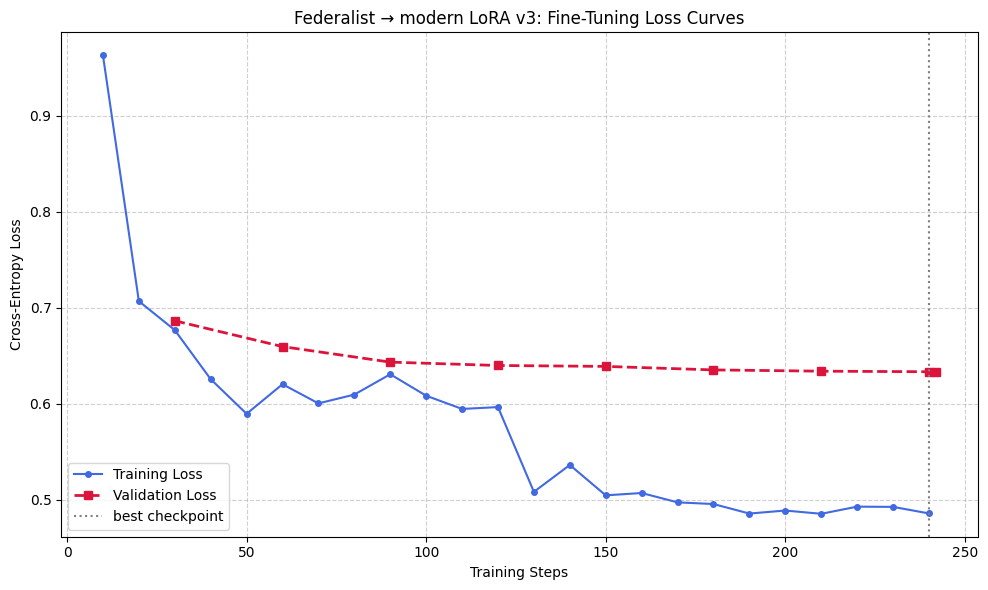

val losses: [(30, 0.6866), (60, 0.6597), (90, 0.6435), (120, 0.64), (150, 0.6391), (180, 0.6354), (210, 0.6341), (240, 0.6335), (242, 0.6336)]  (not comparable to v1/v2: direction and targets changed)


In [ ]:
import matplotlib.pyplot as plt

hist = trainer.state.log_history
tr = [(h["step"], h["loss"]) for h in hist if "loss" in h]
ev = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]

plt.figure(figsize=(10, 6))
plt.plot(*zip(*tr), label="Training Loss", color="royalblue", marker="o", markersize=4)
plt.plot(*zip(*ev), label="Validation Loss", color="crimson", marker="s", linestyle="--", linewidth=2)
best = trainer.state.best_model_checkpoint
if best:
    plt.axvline(int(best.split("-")[-1]), color="gray", linestyle=":", label="best checkpoint")
plt.title("Federalist → modern LoRA v3: Fine-Tuning Loss Curves")
plt.xlabel("Training Steps"); plt.ylabel("Cross-Entropy Loss")
plt.legend(); plt.grid(True, linestyle="--", alpha=0.6); plt.tight_layout()
plt.savefig(OUT_DIR / "loss_curve_v3.png", dpi=150)
plt.show()
print("val losses:", [(s, round(l, 4)) for s, l in ev], " (not comparable to v1/v2: direction and targets changed)")
BEST_CKPT, BEST_LOSS = trainer.state.best_model_checkpoint, trainer.state.best_metric

## 8. Generate outputs for every system on the held-out test chunks
Three systems, same test chunks, same temperature, same seed:

| system | input it receives | prompt |
|---|---|---|
| Qwen-7B zero-shot (teacher) | raw Federalist text | the translator's 5-rule "plain" prompt |
| Qwen-3B zero-shot | raw Federalist text | the same 5-rule prompt (adapter disabled) |
| v3 adapter | entity-masked Federalist text, names restored afterwards | the short training prompt |

The zero-shot systems get the *detailed* prompt on purpose: the adapter has to beat a well-prompted base model to justify fine-tuning. Outputs are cached in `v3/` so a crashed evaluation does not repeat generation. The training model is freed first so the 7B teacher fits in GPU memory.

In [ ]:
try:
    del trainer, model
except NameError:
    pass
gc.collect(); torch.cuda.empty_cache()

eval_set = test_pairs
srcs = [p["original"] for p in eval_set]
refs = [p["modern"] for p in eval_set]
ids  = [p["id"] for p in eval_set]
print(f"{len(eval_set)} held-out test chunks from papers {sorted(set(p['paper'] for p in eval_set))}")

ZS_SYSTEM = system_for({"style": "plain"})
norm = lambda o: re.sub(r"\s*\n+\s*", " ", o).strip()

@torch.no_grad()
def chat_generate(lm, tk, system, users, bs=8, temperature=EVAL_TEMPERATURE, max_new_tokens=450, adapter_off=False):
    prompts = [tk.apply_chat_template([{"role": "system", "content": system}, {"role": "user", "content": u}],
                                      tokenize=False, add_generation_prompt=True) for u in users]
    order = sorted(range(len(users)), key=lambda i: len(prompts[i]))
    outs = [None] * len(users)
    def run(idx):
        enc = tk([prompts[i] for i in idx], return_tensors="pt", padding=True, add_special_tokens=False).to(lm.device)
        kw = dict(max_new_tokens=max_new_tokens, do_sample=True, temperature=temperature, top_p=0.9,
                  repetition_penalty=1.05, pad_token_id=tk.pad_token_id)
        if adapter_off:
            with lm.disable_adapter(): out = lm.generate(**enc, **kw)
        else:
            out = lm.generate(**enc, **kw)
        for j, i in enumerate(idx):
            outs[i] = norm(tk.decode(out[j][enc["input_ids"].shape[1]:], skip_special_tokens=True))
    for s in range(0, len(order), bs):
        idx = order[s:s + bs]
        try:
            run(idx)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            for i in idx: run([i])
    return outs

def cached_outputs(name, fn):
    path = OUT_DIR / ("outputs_" + re.sub(r"\W+", "_", name) + ".json")
    if path.exists():
        d = json.loads(path.read_text(encoding="utf-8"))
        if d["ids"] == ids:
            print(f"  {name}: loaded cached outputs"); return d["outputs"]
    t0 = time.time(); torch.manual_seed(SEED)
    outs = fn()
    path.write_text(json.dumps({"ids": ids, "outputs": outs}), encoding="utf-8")
    print(f"  {name}: generated in {(time.time() - t0) / 60:.1f} min"); return outs

outputs = {}

def gen_7b():
    tm, tt = get_translator()
    return chat_generate(tm, tt, ZS_SYSTEM, srcs, bs=LOCAL_BATCH)
outputs["Qwen-7B zero-shot (teacher)"] = cached_outputs("Qwen-7B zero-shot", gen_7b)
tmodel = ttok = None; gc.collect(); torch.cuda.empty_cache()

69 held-out test chunks from papers [31, 40, 50, 59, 63]


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

  Qwen-7B zero-shot: generated in 1.9 min


In [ ]:
from peft import PeftModel
ADAPTER_DIR = OUT_DIR / "adapter"
assert (ADAPTER_DIR / "adapter_config.json").exists(), "train the adapter first (section 7)"
bf16_ok = torch.cuda.is_bf16_supported(); compute_dtype = torch.bfloat16 if bf16_ok else torch.float16
gtok = AutoTokenizer.from_pretrained(BASE_MODEL, padding_side="left")
if gtok.pad_token is None: gtok.pad_token = gtok.eos_token
base = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL, device_map={"": 0}, torch_dtype=compute_dtype,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                                           bnb_4bit_compute_dtype=compute_dtype))
gm = PeftModel.from_pretrained(base, str(ADAPTER_DIR)); gm.eval()

outputs["Qwen-3B zero-shot"] = cached_outputs("Qwen-3B zero-shot",
    lambda: chat_generate(gm, gtok, ZS_SYSTEM, srcs, adapter_off=True))

def gen_v3():
    ms = [mask_input(t) for t in srcs]
    raw = chat_generate(gm, gtok, SYSTEM_PROMPT, [m for m, _ in ms])
    return [norm(unmask(o, surf)) for o, (_, surf) in zip(raw, ms)]
outputs["v3 adapter"] = cached_outputs("v3 adapter", gen_v3)
print("systems:", list(outputs))

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


  Qwen-3B zero-shot: generated in 1.9 min
  v3 adapter: generated in 3.7 min
systems: ['Qwen-7B zero-shot (teacher)', 'Qwen-3B zero-shot', 'v3 adapter']


## 9. Metrics

In [ ]:
from sacrebleu.metrics import BLEU
from bert_score import BERTScorer
from sentence_transformers import SentenceTransformer
import pandas as pd
from IPython.display import display

dev = "cuda"
assert ARCHAIC_LM_BASE == MODERN_LM, "the two perplexity models share one tokenizer, so they must be the same architecture/vocab"

ctk = AutoTokenizer.from_pretrained(str(clf_dir))
clf = AutoModelForSequenceClassification.from_pretrained(str(clf_dir)).to(dev).eval()
ltok = AutoTokenizer.from_pretrained(str(alm_dir))
alm = AutoModelForCausalLM.from_pretrained(str(alm_dir)).to(dev).eval()
mlm = AutoModelForCausalLM.from_pretrained(MODERN_LM).to(dev).eval()
eval_emb = SentenceTransformer(EVAL_EMBEDDER, device=dev); eval_emb.max_seq_length = 512
bscorer = BERTScorer(model_type=BERTSCORE_MODEL, lang="en", rescale_with_baseline=False, batch_size=16, device=dev)
_bleu = BLEU(effective_order=True)

@torch.no_grad()
def clf_prob(texts, bs=16):
    out = []
    for s in range(0, len(texts), bs):
        enc = ctk(texts[s:s + bs], return_tensors="pt", padding=True, truncation=True, max_length=CLF_MAX_LEN).to(dev)
        out += torch.softmax(clf(**enc).logits.float(), -1)[:, 1].cpu().tolist()
    return np.array(out)

@torch.no_grad()
def lm_nll(lm, texts, bs=8, max_len=1000):
    res = []
    for s in range(0, len(texts), bs):
        enc = [[ltok.bos_token_id] + ltok(t, add_special_tokens=False)["input_ids"][:max_len - 1] for t in texts[s:s + bs]]
        L = max(map(len, enc))
        ids_ = torch.tensor([e + [ltok.eos_token_id] * (L - len(e)) for e in enc]).to(dev)
        att = torch.tensor([[1] * len(e) + [0] * (L - len(e)) for e in enc]).to(dev)
        logits = lm(input_ids=ids_, attention_mask=att).logits[:, :-1].float()
        tgt, m = ids_[:, 1:], att[:, 1:].float()
        nll = torch.nn.functional.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt.reshape(-1), reduction="none").view(tgt.shape)
        res += ((nll * m).sum(1) / m.sum(1)).cpu().tolist()
    return np.array(res)

def cos_pairs(a, b):
    ea = eval_emb.encode(a, batch_size=32, convert_to_tensor=True, normalize_embeddings=True, show_progress_bar=False)
    eb = eval_emb.encode(b, batch_size=32, convert_to_tensor=True, normalize_embeddings=True, show_progress_bar=False)
    return (ea * eb).sum(1).cpu().numpy()

def sari_items(src_, preds, refs_):
    return np.array([_sari.compute(sources=[s], predictions=[p], references=[[r]])["sari"] for s, p, r in zip(src_, preds, refs_)])

ARTIFACT = re.compile(r"\[[A-Z]+(?:_\d+)?\]|(?:^|\n|:\s*)[-•*]\s+\S")
nwords = lambda t: len(t.split())
NAN = np.full(len(eval_set), np.nan)

def score_system(name, texts):
    is_src, is_ref = name.startswith("source"), name.startswith("reference")
    M = {}
    pm = clf_prob(texts); M["clf_p_modern"] = pm; M["clf_is_modern"] = (pm > 0.5).astype(float)
    na, nm = lm_nll(alm, texts), lm_nll(mlm, texts)
    M["ppl_logratio"] = na - nm
    M["ppl_modern"] = np.exp(nm)
    M["bleu_src"] = NAN if is_src else np.array([_bleu.sentence_score(t, [s]).score for t, s in zip(texts, srcs)])
    M["bleu_ref"] = NAN if is_ref else np.array([_bleu.sentence_score(t, [r]).score for t, r in zip(texts, refs)])
    M["bertscore_src"] = NAN if is_src else bscorer.score(texts, srcs)[2].numpy()
    M["bertscore_ref"] = NAN if is_ref else bscorer.score(texts, refs)[2].numpy()
    M["cos_src"] = NAN if is_src else cos_pairs(texts, srcs)
    M["cos_ref"] = NAN if is_ref else cos_pairs(texts, refs)
    M["sari"] = NAN if is_ref else sari_items(srcs, texts, refs)
    M["len_ratio_src"] = NAN if is_src else np.array([nwords(t) / max(1, nwords(s)) for t, s in zip(texts, srcs)])
    M["len_ratio_ref"] = NAN if is_ref else np.array([nwords(t) / max(1, nwords(r)) for t, r in zip(texts, refs)])
    M["artifact"] = np.array([float(bool(ARTIFACT.search(t))) for t in texts])
    return M

all_systems = {"source (Federalist)": srcs, "reference (cached paraphrase)": refs, **outputs}
PER = {}
for name, texts in all_systems.items():
    t0 = time.time(); PER[name] = score_system(name, texts); print(f"  scored {name} ({time.time() - t0:.0f}s)")

long_df = pd.DataFrame([{"system": s, "id": ids[i], **{k: float(v[i]) for k, v in M.items()}} for s, M in PER.items() for i in range(len(ids))])
long_df.to_csv(OUT_DIR / "per_chunk_metrics_v3.csv", index=False)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

... (16 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  scored source (Federalist) (10s)
  scored reference (cached paraphrase) (5s)
  scored Qwen-7B zero-shot (teacher) (8s)
  scored Qwen-3B zero-shot (7s)
  scored v3 adapter (7s)


In [ ]:
# ---------------- aggregate with bootstrap CIs and display ----------------
def boot_ci(v, tf=None):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if len(v) == 0: return None
    rng = np.random.default_rng(SEED)
    means = v[rng.integers(0, len(v), (N_BOOT, len(v)))].mean(1)
    lo, hi = np.percentile(means, [2.5, 97.5]); m = v.mean()
    return (tf(m), tf(lo), tf(hi)) if tf else (m, lo, hi)

def fmt(v, tf=None, pct=False, nd=3):
    r = boot_ci(v, tf)
    if r is None: return "–"
    m, lo, hi = r
    if pct: return f"{100*m:.0f}%  [{100*lo:.0f}, {100*hi:.0f}]"
    return f"{m:.{nd}f}  [{lo:.{nd}f}, {hi:.{nd}f}]"

GROUPS = {
    "Style transfer strength (higher = more modern)": [("clf_is_modern", "classifier acc", dict(pct=True)),
                                                        ("clf_p_modern", "mean P(modern)", {}),
                                                        ("ppl_logratio", "PPL ratio arch/mod (geo-mean)", dict(tf=np.exp, nd=2))],
    "Content preservation (higher = better)": [("bleu_src", "self-BLEU (vs source)", dict(nd=1)), ("bleu_ref", "BLEU (vs ref)", dict(nd=1)),
                                                ("bertscore_src", "BERTScore F1 (vs source)", {}), ("bertscore_ref", "BERTScore F1 (vs ref)", {}),
                                                ("cos_src", "cosine (vs source)", {}), ("cos_ref", "cosine (vs ref)", {})],
    "Simplicity": [("sari", "SARI", dict(nd=1)), ("len_ratio_src", "length ratio out/source", dict(nd=2)), ("len_ratio_ref", "length ratio out/ref", dict(nd=2))],
    "Sanity": [("ppl_modern", "PPL under modern LM (lower = more fluent)", dict(nd=1)), ("artifact", "artifact rate", dict(pct=True))],
}
numeric_rows = []
for title, cols in GROUPS.items():
    tab = {name: {label: fmt(PER[name][k], **kw) for k, label, kw in cols} for name in PER}
    print("\n" + title); display(pd.DataFrame(tab).T)
for name, M in PER.items():
    for k, v in M.items():
        r = boot_ci(v)
        numeric_rows.append({"system": name, "metric": k, "mean": None if r is None else r[0], "ci_lo": None if r is None else r[1], "ci_hi": None if r is None else r[2]})
pd.DataFrame(numeric_rows).to_csv(OUT_DIR / "eval_table_v3.csv", index=False)

# ---------------- calibration check ----------------
src_acc = float(np.nanmean(PER["source (Federalist)"]["clf_is_modern"])); ref_acc = float(np.nanmean(PER["reference (cached paraphrase)"]["clf_is_modern"]))
print(f"\nCALIBRATION: classifier says {100*src_acc:.0f}% of Federalist sources and {100*ref_acc:.0f}% of reference paraphrases are 'modern'.")
if src_acc > 0.1 or ref_acc < 0.8:
    print("  -> The classifier is not cleanly separating the two calibration rows. It may be keying on topic or genre instead of style; "
          "treat its numbers with caution (see the note at the top).")

# ---------------- paired comparison: v3 vs each zero-shot system ----------------
PAIRED = [("clf_p_modern", "P(modern)"), ("ppl_logratio", "log PPL ratio"), ("bertscore_src", "BERTScore vs source"), ("bertscore_ref", "BERTScore vs ref"),
          ("cos_src", "cosine vs source"), ("cos_ref", "cosine vs ref"), ("bleu_ref", "BLEU vs ref"), ("sari", "SARI")]
print("\nPAIRED COMPARISON  (v3 minus other; positive = v3 higher; CI over chunks)")
for other in [s for s in outputs if s != "v3 adapter"]:
    print(f"\n  v3 adapter vs {other}")
    for k, label in PAIRED:
        d = PER["v3 adapter"][k] - PER[other][k]
        m, lo, hi = boot_ci(d)
        sig = "  <- CI excludes 0" if (lo > 0 or hi < 0) else ""
        print(f"    {label:22s} diff {m:+.3f}  [{lo:+.3f}, {hi:+.3f}]  v3 higher on {int((d > 0).sum())}/{len(d)} chunks{sig}")

# ---------------- look at the worst v3 outputs ----------------
worst = np.argsort(PER["v3 adapter"]["bertscore_src"])[:3]
for i in worst:
    print(f"\n--- chunk {ids[i]}: v3 BERTScore vs source {PER['v3 adapter']['bertscore_src'][i]:.3f}")
    print("SOURCE: ", srcs[i][:350]); print("REF:    ", refs[i][:350])
    for s in outputs: print(f"{s[:22]:22s}", outputs[s][i][:350])


Style transfer strength (higher = more modern)


,classifier acc,mean P(modern),PPL ratio arch/mod (geo-mean)
source (Federalist),"0% [0, 0]","0.000 [0.000, 0.000]","0.74 [0.72, 0.76]"
reference (cached paraphrase),"67% [55, 77]","0.673 [0.565, 0.775]","1.09 [1.04, 1.14]"
Qwen-7B zero-shot (teacher),"42% [30, 54]","0.419 [0.306, 0.535]","0.99 [0.95, 1.03]"
Qwen-3B zero-shot,"75% [65, 86]","0.754 [0.652, 0.855]","1.27 [1.19, 1.35]"
v3 adapter,"61% [48, 72]","0.614 [0.488, 0.729]","1.08 [1.03, 1.12]"



Content preservation (higher = better)


,self-BLEU (vs source),BLEU (vs ref),BERTScore F1 (vs source),BERTScore F1 (vs ref),cosine (vs source),cosine (vs ref)
source (Federalist),–,"18.5 [16.1, 21.3]",–,"0.905 [0.900, 0.911]",–,"0.843 [0.825, 0.860]"
reference (cached paraphrase),"17.5 [15.1, 20.3]",–,"0.905 [0.900, 0.911]",–,"0.843 [0.825, 0.860]",–
Qwen-7B zero-shot (teacher),"28.1 [23.6, 32.6]","51.5 [46.9, 55.8]","0.921 [0.914, 0.927]","0.952 [0.947, 0.957]","0.895 [0.880, 0.910]","0.933 [0.919, 0.946]"
Qwen-3B zero-shot,"14.6 [9.5, 20.5]","15.1 [13.3, 17.0]","0.889 [0.880, 0.898]","0.908 [0.903, 0.913]","0.737 [0.707, 0.765]","0.816 [0.792, 0.837]"
v3 adapter,"20.2 [16.4, 24.2]","30.5 [27.5, 33.3]","0.909 [0.903, 0.915]","0.930 [0.926, 0.934]","0.860 [0.835, 0.881]","0.886 [0.865, 0.905]"



Simplicity


,SARI,length ratio out/source,length ratio out/ref
source (Federalist),"44.7 [43.7, 45.9]",–,"1.41 [1.36, 1.46]"
reference (cached paraphrase),–,"0.73 [0.70, 0.75]",–
Qwen-7B zero-shot (teacher),"69.2 [66.3, 71.8]","0.78 [0.75, 0.80]","1.08 [1.04, 1.12]"
Qwen-3B zero-shot,"44.4 [42.7, 46.0]","0.66 [0.63, 0.70]","0.93 [0.87, 0.98]"
v3 adapter,"56.3 [54.5, 58.0]","0.74 [0.71, 0.77]","1.03 [0.99, 1.07]"



Sanity


,PPL under modern LM (lower = more fluent),artifact rate
source (Federalist),"35.0 [32.3, 38.0]","0% [0, 0]"
reference (cached paraphrase),"34.0 [31.2, 36.9]","0% [0, 0]"
Qwen-7B zero-shot (teacher),"35.6 [32.7, 38.7]","0% [0, 0]"
Qwen-3B zero-shot,"50.0 [44.5, 55.9]","0% [0, 0]"
v3 adapter,"36.2 [32.8, 40.1]","0% [0, 0]"



CALIBRATION: classifier says 0% of Federalist sources and 67% of reference paraphrases are 'modern'.
  -> The classifier is not cleanly separating the two calibration rows. It may be keying on topic or genre instead of style; treat its numbers with caution (see the note at the top).

PAIRED COMPARISON  (v3 minus other; positive = v3 higher; CI over chunks)

  v3 adapter vs Qwen-7B zero-shot (teacher)
    P(modern)              diff +0.195  [+0.077, +0.316]  v3 higher on 50/69 chunks  <- CI excludes 0
    log PPL ratio          diff +0.085  [+0.048, +0.121]  v3 higher on 50/69 chunks  <- CI excludes 0
    BERTScore vs source    diff -0.012  [-0.018, -0.006]  v3 higher on 21/69 chunks  <- CI excludes 0
    BERTScore vs ref       diff -0.022  [-0.027, -0.018]  v3 higher on 8/69 chunks  <- CI excludes 0
    cosine vs source       diff -0.035  [-0.058, -0.014]  v3 higher on 23/69 chunks  <- CI excludes 0
    cosine vs ref          diff -0.047  [-0.068, -0.029]  v3 higher on 17/69 chunks  <

## 10. Try your own text (the real use case)
Replace `MY_TEXTS` with your own old-English passages. The three examples below were written for this notebook in an 18th-century manner (they are **not** quotations); the third is deliberately off-topic for the Federalist, to check that the adapter generalizes beyond political text.

In [ ]:
MY_TEXTS = [
    "It is a truth too well attested by experience, that a government which hath not the means of enforcing its own decrees must in the end become the mere shadow of authority; for the States, jealous of their several prerogatives, will withhold what is demanded of them whenever it shall suit their interest.",
    "The advocates of this measure have contended that the danger is chimerical; but I would beseech my fellow citizens to consider whether a prudent people ought to rest the safety of their liberties upon the forbearance of those who possess the power to destroy them.",
    "I write to inform you, good sir, that the ship which bore your goods is arrived in the harbour, albeit with some damage to her rigging, which the master hath promised to repair at his own expense ere she sail again.",
]
torch.manual_seed(SEED)
my = {"Qwen-3B zero-shot": chat_generate(gm, gtok, ZS_SYSTEM, MY_TEXTS, adapter_off=True)}
ms = [mask_input(t) for t in MY_TEXTS]
my["v3 adapter"] = [norm(unmask(o, surf)) for o, (_, surf) in zip(chat_generate(gm, gtok, SYSTEM_PROMPT, [m for m, _ in ms]), ms)]
for i, t in enumerate(MY_TEXTS):
    print("=" * 90); print(f"INPUT {i + 1} (P(modern) = {clf_prob([t])[0]:.2f}): {t}\n")
    for s, outs in my.items():
        o = outs[i]
        print(f"[{s}]  P(modern) {clf_prob([o])[0]:.2f} | length ratio {nwords(o) / nwords(t):.2f} | artifact {bool(ARTIFACT.search(o))}\n{o}\n")

INPUT 1 (P(modern) = 0.00): It is a truth too well attested by experience, that a government which hath not the means of enforcing its own decrees must in the end become the mere shadow of authority; for the States, jealous of their several prerogatives, will withhold what is demanded of them whenever it shall suit their interest.

[Qwen-3B zero-shot]  P(modern) 0.00 | length ratio 0.70 | artifact False
It's true from much experience, that a government without the power to enforce its decisions will eventually lose its authority; states will refuse to comply when it suits them, thus making the government just an empty name.

[v3 adapter]  P(modern) 0.00 | length ratio 0.91 | artifact False
It is a truth well attested by experience that a government without the means to enforce its decrees will eventually become nothing more than a mere shadow of authority. The states, jealous of their own prerogatives, will withhold what is demanded of them whenever it suits their interests.

INPUT 2 (

## 11. Save the run summary

In [ ]:
summary = {
    "config": {k: globals()[k] for k in ["TRANSLATOR_MODEL", "REUSE_BASELINE_TRANSLATIONS", "REUSE_V2_PLAIN_SHORT", "SHORT_FRAC", "MIN_SIM_LONG", "MIN_SIM_SHORT",
                                         "BASE_MODEL", "LORA_R", "LORA_ALPHA", "LORA_DROPOUT", "EPOCHS", "LR", "WEIGHT_DECAY", "SEED", "EVAL_TEMPERATURE",
                                         "CLF_BASE", "ARCHAIC_LM_BASE", "MODERN_LM", "EVAL_EMBEDDER", "BERTSCORE_MODEL", "N_BOOT", "WIKI_TOPIC_FILTER"]},
    "data": {"train": len(train_pairs), "train_kinds": dict(Counter(p["kind"] for p in train_pairs)), "val": len(val_pairs), "test": len(test_pairs)},
    "best_checkpoint": BEST_CKPT, "best_eval_loss": BEST_LOSS,
    "classifier_validation": CLF_VAL,
    "calibration": {"federalist_source_pct_modern": src_acc, "reference_pct_modern": ref_acc},
    "eval_table": numeric_rows,
    "test_outputs": outputs,
    "my_text_outputs": my,
}
(OUT_DIR / "run_summary_v3.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
print("files in", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()): print("  ", p.name)

files in /content/drive/MyDrive/federalist_lora/v3
   adapter
   checkpoints
   eval_models
   eval_table_v3.csv
   loss_curve_v3.png
   outputs_Qwen_3B_zero_shot.json
   outputs_Qwen_7B_zero_shot.json
   outputs_v3_adapter.json
   pairs_v3_audit.jsonl
   per_chunk_metrics_v3.csv
   run_summary_v3.json
   translations_v3.jsonl


## Using the adapter later
```python
from peft import PeftModel
base = AutoModelForCausalLM.from_pretrained(BASE_MODEL, quantization_config=..., device_map={"": 0})
model = PeftModel.from_pretrained(base, WORKDIR / "v3" / "adapter")
```
Use `mask_input` / `unmask` from section 3 around generation, and the same `SYSTEM_PROMPT` from section 4.

**Reading the section 9 tables.** A better adapter has a higher classifier rate and PPL ratio than Qwen-3B zero-shot while keeping BERTScore/cosine (vs source) at least as high, and a length ratio that is not collapsing toward 0. Check the calibration row first: if the classifier does not label the Federalist source as archaic and the reference as modern, its numbers are not trustworthy. If v3 is not clearly ahead of the zero-shot systems (paired CIs excluding 0), the knobs to try next are the similarity floors in the config (`MIN_SIM_*`), more training data, or `TRANSLATOR_MODEL = "Qwen/Qwen2.5-14B-Instruct"` with `REUSE_BASELINE_TRANSLATIONS = False` and `REUSE_V2_PLAIN_SHORT = False`.

In [ ]:
print("classifier validation on held-out VAL papers vs held-out Wikipedia:", CLF_VAL)

refp = PER["reference (cached paraphrase)"]["clf_p_modern"]
low = np.where(refp < 0.5)[0]
print(f"\n{len(low)}/{len(refp)} reference paraphrases are classified as NOT modern. The 5 lowest:")
print("  -> if these still read archaic, the references are lightly modernized and the classifier is right;")
print("     if they read plain, the classifier is the problem (topic/genre confound).\n")
for i in low[np.argsort(refp[low])][:5]:
    print(f"  {ids[i]}  P(modern)={refp[i]:.2f}\n    SOURCE: {srcs[i][:220]}\n    REF:    {refs[i][:320]}\n")

print("share of outputs that are near-verbatim copies of the source (sentence-BLEU vs source):")
for s in outputs:
    b = PER[s]["bleu_src"]
    print(f"  {s:32s} >80: {np.mean(b > 80):4.0%}   >60: {np.mean(b > 60):4.0%}")

classifier validation on held-out VAL papers vs held-out Wikipedia: {'accuracy': 0.9981949458483754, 'archaic_recall': 0.9963898916967509, 'modern_recall': 1.0}

23/69 reference paraphrases are classified as NOT modern. The 5 lowest:
  -> if these still read archaic, the references are lightly modernized and the classifier is right;
     if they read plain, the classifier is the problem (topic/genre confound).

  fed40_06  P(modern)=0.00
    SOURCE: But is it necessary to suppose that these expressions are absolute irreconcilable to each other; that no alterations or provisions in the articles of the Confederation could possibly mound them into a national and adequa
    REF:    But is it necessary to assume that these expressions are absolutely incompatible with each other? That no changes or additions to the articles of the Confederation could ever turn them into a national and effective government, as proposed by the convention?

  fed40_18  P(modern)=0.00
    SOURCE: But that the ob

In [ ]:
def count_syl(w):
    w = re.sub(r"[^a-z]", "", w.lower())
    if not w: return 0
    n = len(re.findall(r"[aeiouy]+", w))
    if w.endswith("e") and not w.endswith(("le", "ee")) and n > 1: n -= 1
    if w.endswith("ed") and not re.search(r"[td]ed$", w) and n > 1: n -= 1
    return max(1, n)

def readability(text):
    sents = [s for s in split_sentences(text) if s.strip()] or [text]
    words = re.findall(r"[A-Za-z']+", text)
    if not words: return (np.nan,) * 4
    syl = [count_syl(w) for w in words]
    wps, spw = len(words) / len(sents), sum(syl) / len(words)
    return (0.39 * wps + 11.8 * spw - 15.59,
            wps,
            spw,
            100 * float(np.mean([x >= 3 for x in syl])))

for name, texts in all_systems.items():
    R = np.array([readability(t) for t in texts])
    PER[name].update(fkgl=R[:, 0], sent_len=R[:, 1], syl_per_word=R[:, 2], complex_pct=R[:, 3])

tab = {n: {"FKGL grade": fmt(PER[n]["fkgl"], nd=1), "words/sentence": fmt(PER[n]["sent_len"], nd=1),
           "syllables/word": fmt(PER[n]["syl_per_word"], nd=2), "% complex words": fmt(PER[n]["complex_pct"], nd=1)} for n in PER}
print("Readability (lower = easier). FKGL uses a heuristic syllable counter, so compare rows, not absolute grades.")
display(pd.DataFrame(tab).T)

print("\nPAIRED: FKGL, v3 minus other (negative = v3 is easier)")
for other in [s for s in PER if s != "v3 adapter"]:
    d = PER["v3 adapter"]["fkgl"] - PER[other]["fkgl"]; m, lo, hi = boot_ci(d)
    print(f"  vs {other:32s} {m:+.2f}  [{lo:+.2f}, {hi:+.2f}]" + ("   <- CI excludes 0" if (lo > 0 or hi < 0) else ""))
print("\nCaution: FKGL falls when sentences are chopped short, with no change in vocabulary. Read it next to '% complex words'.")

Readability (lower = easier). FKGL uses a heuristic syllable counter, so compare rows, not absolute grades.


,FKGL grade,words/sentence,syllables/word,% complex words
source (Federalist),"20.5 [18.8, 22.4]","42.6 [38.4, 47.5]","1.65 [1.63, 1.67]","19.4 [18.6, 20.1]"
reference (cached paraphrase),"13.3 [12.4, 14.2]","24.2 [22.2, 26.6]","1.64 [1.62, 1.67]","18.0 [17.0, 19.1]"
Qwen-7B zero-shot (teacher),"15.2 [13.9, 16.8]","28.7 [25.6, 32.4]","1.66 [1.64, 1.69]","18.9 [17.9, 20.0]"
Qwen-3B zero-shot,"11.1 [10.0, 12.3]","23.6 [21.0, 26.4]","1.48 [1.46, 1.51]","12.3 [11.2, 13.5]"
v3 adapter,"13.8 [12.7, 15.0]","25.0 [22.5, 28.1]","1.66 [1.64, 1.69]","18.6 [17.5, 19.7]"



PAIRED: FKGL, v3 minus other (negative = v3 is easier)
  vs source (Federalist)              -6.71  [-8.35, -5.29]   <- CI excludes 0
  vs reference (cached paraphrase)    +0.56  [-0.51, +1.62]
  vs Qwen-7B zero-shot (teacher)      -1.44  [-2.66, -0.60]   <- CI excludes 0
  vs Qwen-3B zero-shot                +2.69  [+1.28, +3.99]   <- CI excludes 0

Caution: FKGL falls when sentences are chopped short, with no change in vocabulary. Read it next to '% complex words'.


In [ ]:
NLI_NAME = "roberta-large-mnli"
ntok = AutoTokenizer.from_pretrained(NLI_NAME)
nli = AutoModelForSequenceClassification.from_pretrained(NLI_NAME).to(dev).eval()
id2l = {int(k): v.lower() for k, v in nli.config.id2label.items()}
iE = next(k for k, v in id2l.items() if v.startswith("entail")); iC = next(k for k, v in id2l.items() if v.startswith("contra"))
print("NLI labels:", id2l)

@torch.no_grad()
def nli_probs(prem, hyp, bs=32):
    E, C = [], []
    for s in range(0, len(prem), bs):
        enc = ntok(prem[s:s + bs], hyp[s:s + bs], return_tensors="pt", padding=True, truncation="only_first", max_length=400).to(dev)
        with torch.autocast("cuda", dtype=torch.float16):
            p = torch.softmax(nli(**enc).logits.float(), -1)
        E += p[:, iE].cpu().tolist(); C += p[:, iC].cpu().tolist()
    return np.array(E), np.array(C)

def windows(sents): return sents + [sents[i] + " " + sents[i + 1] for i in range(len(sents) - 1)]

def best_support(prem_sents, hyp_sents):
    W = windows(prem_sents)
    pairs = [(w, h) for h in hyp_sents for w in W]
    E, C = nli_probs([p for p, _ in pairs], [h for _, h in pairs])
    E, C = E.reshape(len(hyp_sents), len(W)), C.reshape(len(hyp_sents), len(W))
    return E.max(1), C.max(1), E.argmax(1)

def nli_chunk(src_text, out_text):
    ss, oo = split_sentences(src_text), split_sentences(out_text)
    if not ss or not oo: return [np.nan] * 5, None
    Eo, Co, arg = best_support(ss, oo)
    Es, _, _ = best_support(oo, ss)
    contra = float(np.mean((Eo < 0.5) & (Co > 0.5)))
    return [float(Eo.mean()), float((Eo >= 0.5).mean()), float(Es.mean()), float((Es >= 0.5).mean()), contra], (oo, Eo, arg, windows(ss))

NLI_ROWS = ["reference (cached paraphrase)", *outputs]
detail = {}
for name in PER:
    if name not in NLI_ROWS:
        for k in ("nli_faith", "faith_frac", "nli_cover", "cover_frac", "nli_contra"): PER[name][k] = np.full(len(ids), np.nan)
        continue
    t0 = time.time(); rows, detail[name] = [], []
    for i in range(len(ids)):
        r, d = nli_chunk(srcs[i], all_systems[name][i]); rows.append(r); detail[name].append(d)
    R = np.array(rows)
    for j, k in enumerate(("nli_faith", "faith_frac", "nli_cover", "cover_frac", "nli_contra")):
        PER[name][k] = R[:, j]
    print(f"  NLI scored {name} ({(time.time() - t0) / 60:.1f} min)")
del nli; gc.collect(); torch.cuda.empty_cache()

tab = {n: {"faithfulness (mean best-entail)": fmt(PER[n]["nli_faith"]), "% output sentences supported": fmt(PER[n]["faith_frac"], pct=True),
           "coverage (mean best-entail)": fmt(PER[n]["nli_cover"]), "% source sentences covered": fmt(PER[n]["cover_frac"], pct=True),
           "% output sentences contradicted": fmt(PER[n]["nli_contra"], pct=True)} for n in NLI_ROWS}
display(pd.DataFrame(tab).T)

print("\nPAIRED (v3 minus other; positive = v3 higher; for 'contradicted' lower is better)")
for other in [s for s in NLI_ROWS if s != "v3 adapter"]:
    print(f"\n  v3 adapter vs {other}")
    for k, label in [("nli_faith", "faithfulness"), ("faith_frac", "% sentences supported"), ("nli_cover", "coverage"), ("cover_frac", "% source covered"), ("nli_contra", "% contradicted")]:
        d = PER["v3 adapter"][k] - PER[other][k]; m, lo, hi = boot_ci(d)
        print(f"    {label:24s} {m:+.3f}  [{lo:+.3f}, {hi:+.3f}]" + ("   <- CI excludes 0" if (lo > 0 or hi < 0) else ""))

cand = [(Eo[j], i, j) for i, d in enumerate(detail["v3 adapter"]) if d is not None for j, _ in enumerate(d[0]) for Eo in [d[1]]]
print("\nLEAST-SUPPORTED v3 OUTPUT SENTENCES (check these by hand for meaning errors):")
for e, i, j in sorted(cand)[:8]:
    oo, Eo, arg, W = detail["v3 adapter"][i]
    print(f"\n  chunk {ids[i]} | support {e:.2f}\n    OUTPUT: {oo[j][:260]}\n    BEST SOURCE WINDOW: {W[arg[j]][:300]}")

config.json:   0%|          | 0.00/688 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.43GB            

... (2 outputs left out)

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-large-mnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


NLI labels: {0: 'contradiction', 1: 'neutral', 2: 'entailment'}
  NLI scored reference (cached paraphrase) (0.3 min)
  NLI scored Qwen-7B zero-shot (teacher) (0.3 min)
  NLI scored Qwen-3B zero-shot (0.3 min)
  NLI scored v3 adapter (0.3 min)


,faithfulness (mean best-entail),% output sentences supported,coverage (mean best-entail),% source sentences covered,% output sentences contradicted
reference (cached paraphrase),"0.943 [0.926, 0.958]","97% [96, 99]","0.765 [0.716, 0.806]","81% [74, 86]","1% [0, 2]"
Qwen-7B zero-shot (teacher),"0.966 [0.955, 0.976]","99% [98, 100]","0.831 [0.789, 0.869]","86% [80, 91]","0% [0, 1]"
Qwen-3B zero-shot,"0.848 [0.808, 0.884]","87% [82, 91]","0.675 [0.619, 0.728]","69% [61, 75]","4% [2, 6]"
v3 adapter,"0.913 [0.884, 0.939]","93% [90, 96]","0.765 [0.715, 0.810]","79% [73, 85]","2% [1, 4]"



PAIRED (v3 minus other; positive = v3 higher; for 'contradicted' lower is better)

  v3 adapter vs reference (cached paraphrase)
    faithfulness             -0.030  [-0.062, -0.001]   <- CI excludes 0
    % sentences supported    -0.042  [-0.078, -0.008]   <- CI excludes 0
    coverage                 +0.000  [-0.059, +0.054]
    % source covered         -0.016  [-0.099, +0.062]
    % contradicted           +0.010  [-0.009, +0.031]

  v3 adapter vs Qwen-7B zero-shot (teacher)
    faithfulness             -0.054  [-0.084, -0.027]   <- CI excludes 0
    % sentences supported    -0.060  [-0.093, -0.028]   <- CI excludes 0
    coverage                 -0.066  [-0.129, -0.007]   <- CI excludes 0
    % source covered         -0.067  [-0.152, +0.014]
    % contradicted           +0.018  [+0.001, +0.040]   <- CI excludes 0

  v3 adapter vs Qwen-3B zero-shot
    faithfulness             +0.065  [+0.020, +0.111]   <- CI excludes 0
    % sentences supported    +0.062  [+0.011, +0.112]   <- CI e

In [ ]:
THR = dict(p_modern=0.5,
           faith_frac=0.75,
           cover_frac=0.75,
           fkgl_drop=2.0,
           ppl_mult=1.5)
ppl_cap = THR["ppl_mult"] * np.median(PER["reference (cached paraphrase)"]["ppl_modern"])
print(f"fluency cap: PPL under modern LM <= {ppl_cap:.1f}\n")

def criteria(name):
    M = PER[name]
    return {"modern": M["clf_p_modern"] > THR["p_modern"],
            "faithful": M["faith_frac"] >= THR["faith_frac"],
            "complete": M["cover_frac"] >= THR["cover_frac"],
            "simpler": (PER["source (Federalist)"]["fkgl"] - M["fkgl"]) >= THR["fkgl_drop"],
            "fluent": M["ppl_modern"] <= ppl_cap,
            "no artifacts": M["artifact"] == 0}

JOINT = {}
rows = {}
for name in NLI_ROWS:
    c = criteria(name); joint = np.all(np.stack(list(c.values())), axis=0).astype(float); JOINT[name] = joint; PER[name]["joint_pass"] = joint
    rows[name] = {**{k: fmt(v.astype(float), pct=True) for k, v in c.items()}, "ALL (joint pass)": fmt(joint, pct=True)}
print("Share of chunks passing each criterion, and all of them together:")
display(pd.DataFrame(rows).T)
print("The 'reference' row shows what is achievable with these thresholds. If even it scores low, a threshold is too strict.")

print("\nPAIRED: joint pass, v3 minus other")
for other in [s for s in NLI_ROWS if s != "v3 adapter"]:
    d = JOINT["v3 adapter"] - JOINT[other]; m, lo, hi = boot_ci(d)
    print(f"  vs {other:32s} {100*m:+.0f} pts  [{100*lo:+.0f}, {100*hi:+.0f}]" + ("   <- CI excludes 0" if (lo > 0 or hi < 0) else ""))

fluency cap: PPL under modern LM <= 48.1

Share of chunks passing each criterion, and all of them together:


,modern,faithful,complete,simpler,fluent,no artifacts,ALL (joint pass)
reference (cached paraphrase),"67% [55, 77]","99% [96, 100]","71% [59, 81]","81% [71, 90]","90% [83, 97]","100% [100, 100]","33% [22, 45]"
Qwen-7B zero-shot (teacher),"42% [30, 54]","100% [100, 100]","78% [68, 87]","70% [58, 80]","90% [83, 97]","100% [100, 100]","25% [14, 35]"
Qwen-3B zero-shot,"75% [65, 86]","81% [71, 90]","52% [41, 64]","88% [81, 96]","58% [46, 70]","100% [100, 100]","12% [4, 20]"
v3 adapter,"61% [48, 72]","93% [87, 99]","68% [57, 78]","84% [75, 93]","84% [75, 93]","100% [100, 100]","28% [17, 39]"


The 'reference' row shows what is achievable with these thresholds. If even it scores low, a threshold is too strict.

PAIRED: joint pass, v3 minus other
  vs reference (cached paraphrase)    -6 pts  [-20, +9]
  vs Qwen-7B zero-shot (teacher)      +3 pts  [-9, +14]
  vs Qwen-3B zero-shot                +16 pts  [+3, +29]   <- CI excludes 0


In [ ]:
N_HUMAN = 40
SYS_X, SYS_Y = "v3 adapter", "Qwen-7B zero-shot (teacher)"
rng = np.random.default_rng(SEED)
pick = sorted(rng.choice(len(ids), size=min(N_HUMAN, len(ids)), replace=False).tolist())      # random, not cherry-picked
a_is_x = rng.random(len(pick)) < 0.5                                                          # randomize which system is "A"

sheet, key = [], []
for n, (i, ax) in enumerate(zip(pick, a_is_x), 1):
    A, B = (SYS_X, SYS_Y) if ax else (SYS_Y, SYS_X)
    sheet.append({"item": n, "chunk_id": ids[i], "SOURCE": srcs[i], "OUTPUT_A": outputs[A][i], "OUTPUT_B": outputs[B][i],
                  "faithful (A/B/tie)": "", "simpler (A/B/tie)": "", "fluent (A/B/tie)": "", "overall (A/B/tie)": "",
                  "meaning_errors_A": "", "meaning_errors_B": "", "notes": ""})
    key.append({"item": n, "chunk_id": ids[i], "A": A, "B": B})
HUMAN_CSV, HUMAN_KEY = OUT_DIR / "human_eval_v3_vs_7b.csv", OUT_DIR / "human_eval_key_DO_NOT_OPEN.csv"
pd.DataFrame(sheet).to_csv(HUMAN_CSV, index=False); pd.DataFrame(key).to_csv(HUMAN_KEY, index=False)
(OUT_DIR / "human_eval_README.txt").write_text(
    "For each item, read SOURCE, then OUTPUT_A and OUTPUT_B (system identities are hidden and randomized).\n"
    "faithful: which keeps the source's meaning better (fewer dropped/changed/invented claims)?\n"
    "simpler: which is easier to read for a modern general reader?\n"
    "fluent: which reads more naturally as English?\n"
    "overall: which would you rather hand to a reader?\n"
    "Answer A, B or tie. meaning_errors_A/B: number of claims that are wrong, missing, or invented.\n"
    "Do NOT open the key file until you have finished.\n")
print(f"wrote {len(sheet)} blind items to:\n  {HUMAN_CSV}\nkey (open only after scoring):\n  {HUMAN_KEY}")
print("Open the CSV in Sheets/Excel, fill the rating columns, save, and run CELL 6. Ideally 2 raters, scored separately.")

wrote 40 blind items to:
  /content/drive/MyDrive/federalist_lora/v3/human_eval_v3_vs_7b.csv
key (open only after scoring):
  /content/drive/MyDrive/federalist_lora/v3/human_eval_key_DO_NOT_OPEN.csv
Open the CSV in Sheets/Excel, fill the rating columns, save, and run CELL 6. Ideally 2 raters, scored separately.


In [ ]:
from scipy.stats import binomtest
HUMAN_FILLED = HUMAN_CSV
hs, hk = pd.read_csv(HUMAN_FILLED), pd.read_csv(HUMAN_KEY)
hs = hs.merge(hk[["item", "A", "B"]], on="item")
print(f"{len(hs)} items\n")
for col, label in [("faithful (A/B/tie)", "faithful"), ("simpler (A/B/tie)", "simpler"), ("fluent (A/B/tie)", "fluent"), ("overall (A/B/tie)", "overall")]:
    c = hs[col].astype(str).str.strip().str.upper()
    win = {SYS_X: 0, SYS_Y: 0}; ties = 0
    for ch, a, b in zip(c, hs["A"], hs["B"]):
        if ch == "A": win[a] += 1
        elif ch == "B": win[b] += 1
        elif ch in ("TIE", "T"): ties += 1
    n = win[SYS_X] + win[SYS_Y]
    p = binomtest(win[SYS_X], n, 0.5).pvalue if n else float("nan")
    print(f"{label:9s} {SYS_X}: {win[SYS_X]:2d} | {SYS_Y}: {win[SYS_Y]:2d} | ties: {ties:2d} | v3 share of decisive items {win[SYS_X] / max(n, 1):.0%} | sign test p = {p:.3f}")

hs["err_x"] = np.where(hs["A"] == SYS_X, pd.to_numeric(hs["meaning_errors_A"], errors="coerce"), pd.to_numeric(hs["meaning_errors_B"], errors="coerce"))
hs["err_y"] = np.where(hs["A"] == SYS_Y, pd.to_numeric(hs["meaning_errors_A"], errors="coerce"), pd.to_numeric(hs["meaning_errors_B"], errors="coerce"))
print(f"\nmeaning errors per chunk: {SYS_X} {hs['err_x'].mean():.2f} | {SYS_Y} {hs['err_y'].mean():.2f}")

40 items

faithful  v3 adapter:  0 | Qwen-7B zero-shot (teacher):  0 | ties:  0 | v3 share of decisive items 0% | sign test p = nan
simpler   v3 adapter:  0 | Qwen-7B zero-shot (teacher):  0 | ties:  0 | v3 share of decisive items 0% | sign test p = nan
fluent    v3 adapter:  0 | Qwen-7B zero-shot (teacher):  0 | ties:  0 | v3 share of decisive items 0% | sign test p = nan
overall   v3 adapter:  0 | Qwen-7B zero-shot (teacher):  0 | ties:  0 | v3 share of decisive items 0% | sign test p = nan

meaning errors per chunk: v3 adapter nan | Qwen-7B zero-shot (teacher) nan


In [ ]:
import textwrap, re
from scipy.stats import spearmanr, wilcoxon
N_MINI = 15
SYS_X, SYS_Y = "v3 adapter", "Qwen-7B zero-shot (teacher)"
LIK_PATH = OUT_DIR / "human_eval_likert.json"
REDO = []

rng = np.random.default_rng(SEED + 7)
pick = sorted(rng.choice(len(ids), size=N_MINI, replace=False).tolist())
a_is_x = rng.random(N_MINI) < 0.5
items_h = []
for i, ax in zip(pick, a_is_x):
    A, B = (SYS_X, SYS_Y) if ax else (SYS_Y, SYS_X)
    items_h.append(dict(chunk_id=ids[i], idx=i, A=A, B=B))

done = {d["chunk_id"]: d for d in json.loads(LIK_PATH.read_text())} if LIK_PATH.exists() else {}
for n in REDO:
    done.pop(items_h[n - 1]["chunk_id"], None)
LIK_PATH.write_text(json.dumps(list(done.values())))

wrap = lambda t: textwrap.fill(t, 110)
def ask(prompt, pattern):
    while True:
        a = input(prompt).strip().lower()
        if a == "q" or re.fullmatch(pattern, a): return a
        print("   not valid, try again")

RUBRIC = """RATE EACH OUTPUT 1-5 ON THREE AXES (5 = best on every axis):
  MEANING     5 = every claim of the source kept, nothing wrong, missing or invented | 3 = minor loss or shift | 1 = clearly wrong or much missing
  SIMPLICITY  5 = easy for a modern general reader (everyday words, short sentences)  | 3 = readable but still formal | 1 = as hard as the source
  FLUENCY     5 = natural English | 3 = understandable but awkward | 1 = broken
Type the three digits together, e.g. 453 = meaning 4, simplicity 5, fluency 3.
MEANING ERRORS = a claim that is wrong, missing or invented. Count these against the source sentence by sentence; do not let overall polish decide it.
"""
print(f"{len(done)} of {N_MINI} already rated. System names stay hidden until all {N_MINI} are done. Type q at any prompt to stop (progress is kept).\n")
print(RUBRIC)

stop = False
for n, h in enumerate(items_h, 1):
    if h["chunk_id"] in done: continue
    i = h["idx"]
    while True:
        print("=" * 110); print(f"ITEM {n}/{N_MINI}\n")
        print("SOURCE:\n" + wrap(srcs[i])); print("\nOUTPUT A:\n" + wrap(outputs[h["A"]][i])); print("\nOUTPUT B:\n" + wrap(outputs[h["B"]][i])); print()
        ra = ask("A: meaning/simplicity/fluency as 3 digits (1-5): ", r"[1-5]{3}")
        if ra == "q": stop = True; break
        ea = ask("A: meaning errors (0-9): ", r"[0-9]")
        if ea == "q": stop = True; break
        rb = ask("B: meaning/simplicity/fluency as 3 digits (1-5): ", r"[1-5]{3}")
        if rb == "q": stop = True; break
        eb = ask("B: meaning errors (0-9): ", r"[0-9]")
        if eb == "q": stop = True; break
        note = input("Brief note on the worst problem (Enter to skip): ").strip() if int(ea) + int(eb) > 0 else ""
        print(f"\n  A: meaning {ra[0]}, simplicity {ra[1]}, fluency {ra[2]}, errors {ea}   |   B: meaning {rb[0]}, simplicity {rb[1]}, fluency {rb[2]}, errors {eb}")
        c = input("  Enter = save this item | r = redo it | q = stop without saving it: ").strip().lower()
        if c == "r": print(); continue
        if c == "q": stop = True; break
        done[h["chunk_id"]] = {**h, "rat_A": [int(x) for x in ra], "rat_B": [int(x) for x in rb], "err_A": int(ea), "err_B": int(eb), "note": note}
        LIK_PATH.write_text(json.dumps(list(done.values())))
        break
    if stop: break

if len(done) < N_MINI:
    print(f"\n{len(done)}/{N_MINI} rated so far. Rerun this cell to continue; results appear once all {N_MINI} are done.")
else:
    AX = ["meaning", "simplicity", "fluency"]
    order = [h["chunk_id"] for h in items_h]
    S = {SYS_X: {a: [] for a in AX + ["errors"]}, SYS_Y: {a: [] for a in AX + ["errors"]}}
    idx_of = {h["chunk_id"]: h["idx"] for h in items_h}
    for cid in order:
        d = done[cid]
        for slot in "AB":
            s = d[slot]
            for k, a in enumerate(AX): S[s][a].append(d["rat_" + slot][k])
            S[s]["errors"].append(d["err_" + slot])
    S = {s: {a: np.array(v, float) for a, v in dd.items()} for s, dd in S.items()}

    print("\n" + "=" * 70 + f"\nRESULTS ({N_MINI} blind items; Likert 1-5, higher = better; bootstrap 95% CI)\n" + "=" * 70)
    rows = {}
    for s in (SYS_X, SYS_Y):
        rows[s] = {a: "%.2f  [%.2f, %.2f]" % boot_ci(S[s][a]) for a in AX}
        rows[s]["meaning errors / chunk"] = "%.2f  [%.2f, %.2f]" % boot_ci(S[s]["errors"])
        rows[s]["chunks with >=1 error"] = f"{int((S[s]['errors'] > 0).sum())}/{N_MINI}"
    display(pd.DataFrame(rows).T)

    print("PAIRED, per chunk (v3 minus 7B):")
    for a in AX + ["errors"]:
        d = S[SYS_X][a] - S[SYS_Y][a]; m, lo, hi = boot_ci(d)
        try: p = wilcoxon(d).pvalue if np.any(d != 0) else float("nan")
        except Exception: p = float("nan")
        lbl = "errors (lower is better)" if a == "errors" else a
        print(f"  {lbl:26s} diff {m:+.2f}  [{lo:+.2f}, {hi:+.2f}] | v3 better on {int((d > 0).sum() if a != 'errors' else (d < 0).sum())}, "
              f"7B better on {int((d < 0).sum() if a != 'errors' else (d > 0).sum())}, tied {int((d == 0).sum())} | Wilcoxon p = {p:.3f}")

    print("\nDO THE AUTOMATIC METRICS AGREE WITH YOU? (Spearman rho over the 30 rated outputs; the two outputs of a chunk are not independent, so treat as rough)")
    CHECKS = [("meaning", "faith_frac", "+"), ("meaning", "bertscore_src", "+"), ("meaning", "cos_src", "+"), ("errors", "nli_faith", "-"),
              ("simplicity", "fkgl", "-"), ("simplicity", "complex_pct", "-"), ("fluency", "ppl_modern", "-")]
    for ha, mk, sign in CHECKS:
        try:
            xs = np.concatenate([S[s][ha] for s in (SYS_X, SYS_Y)])
            ys = np.concatenate([[PER[s][mk][idx_of[c]] for c in order] for s in (SYS_X, SYS_Y)])
            rho = spearmanr(xs, ys).statistic
            print(f"  human {ha:10s} vs {mk:14s} rho = {rho:+.2f}   (expected sign: {sign})")
        except Exception as e:
            print(f"  human {ha:10s} vs {mk:14s} not available ({type(e).__name__})")

    print("\nnotes you wrote:")
    for cid in order:
        d = done[cid]
        if d["note"]:
            who = [s for s, e in ((d["A"], d["err_A"]), (d["B"], d["err_B"])) if e > 0]
            print(f"  {cid} ({' & '.join(who)}): {d['note']}")
    print("\n15 items = descriptive evidence, not a significance test. Report means, counts, and the example errors.")

0 of 15 already rated. System names stay hidden until all 15 are done. Type q at any prompt to stop (progress is kept).

RATE EACH OUTPUT 1-5 ON THREE AXES (5 = best on every axis):
  MEANING     5 = every claim of the source kept, nothing wrong, missing or invented | 3 = minor loss or shift | 1 = clearly wrong or much missing
  SIMPLICITY  5 = easy for a modern general reader (everyday words, short sentences)  | 3 = readable but still formal | 1 = as hard as the source
  FLUENCY     5 = natural English | 3 = understandable but awkward | 1 = broken
Type the three digits together, e.g. 453 = meaning 4, simplicity 5, fluency 3.
MEANING ERRORS = a claim that is wrong, missing or invented. Count these against the source sentence by sentence; do not let overall polish decide it.

ITEM 1/15

SOURCE:
IN DISQUISITIONS of every kind, there are certain primary truths, or first principles, upon which all
subsequent reasonings must depend. These contain an internal evidence which, antecedent to al

KeyboardInterrupt: Interrupted by user